# Gate drive has a cost: a reproducible SKY130 LDO sizing laboratory

**Author and travel representative: Christian Reivan**  
**GitHub: [christianreivan](https://github.com/christianreivan)**  
SSCS Code a Chip submission for ISSCC 2027

An LDO pass device must carry the load with the gate swing its driver can actually supply.
This notebook makes that dependency visible using native SKY130 compact model data.
At a PFET source to drain voltage of 100 mV, the first width estimate for 50 mA changes
from approximately **3.05 mm to 10.97 mm** when the available source to gate voltage
changes from 1.8 V to 1.2 V. More width also brings more gate loading.

The contribution is an executable educational workflow that connects three often
separate design steps: current capacity at the intended dropout, closure of a
transconductance sizing calculation, and measurement of actual terminal loading.
It preserves the native tables and checks their provenance before producing a plot.

**What runs here:** Run All verifies and analyzes saved ngspice results and redraws
the figures. It needs no laboratory connection or PDK download. Section 7 supplies
an explicit optional path to regenerate the transistor experiments in native ngspice.
The saved evidence uses ngspice 41, SKY130, TT, and 27 degrees C.

**Scope:** These are transistor characterization and sizing experiments. They do not
claim a complete regulator, a regulated dropout specification, a PSR record, or silicon measurements.


## 1. Start from traceable native data

The public package contains 18 device lookup slices spanning NFET and PFET, three
channel lengths, and three drain voltage magnitudes. It also includes PFET dropout
sweeps, the final native sizing fixture, and two terminal current experiments.
The data files are preserved from completed native ngspice runs. The include path in
each portable SPICE deck is replaced by a configurable public PDK path.

Run this notebook from its own directory. Install `requirements.txt` once if needed.
The checks below verify the evidence hashes and independently recover numerical
landmarks from the native tables.


In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown

PROJECT = Path.cwd()
assert (PROJECT / 'scripts/device_lab.py').is_file(), 'Open the notebook from its project directory'
sys.path.insert(0, str(PROJECT / 'scripts'))
import device_lab as lab

plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
                     'figure.dpi': 120, 'savefig.dpi': 150})
audit = lab.verify_saved_data()
display(pd.Series(audit, name='Saved native evidence check').to_frame())


,Saved native evidence check
native_evidence_files_verified,33
lookup_rows,6498
dropout_width_estimate_um,3050.872803
sizing_final_gm_uS,99.999793
evidence_class,Replay of saved native ngspice compact model data


In [2]:
evidence = json.loads((PROJECT / 'FOUNDATIONAL_EVIDENCE.json').read_text())
display(pd.Series({k: evidence[k] for k in
                   ['simulator', 'PDK_package', 'corner', 'temperature_C', 'evidence_class']},
                  name='Original simulation provenance').to_frame())


,Original simulation provenance
simulator,ngspice 41
PDK_package,open_pdks.sky130a 1.0.471_0_g97d0844 20240223_...
corner,tt
temperature_C,27
evidence_class,Saved native ngspice compact model simulations...


## 2. Size for the gate voltage that exists

<img src="figures/fixture_pfet_dropout.png" alt="PFET dropout fixture" width="720">

The PFET uses `sky130_fd_pr__pfet_01v8`, $W=5\,\mu\mathrm m$ and
$L=0.30\,\mu\mathrm m$. Its source and body are at 1.8 V. Its gate is
$1.8-V_{SG}$ and its drain is $1.8-V_{SD}$. Thus the body bias is zero.
The voltage sources define a device measurement fixture. There is no error amplifier
or feedback loop in this experiment.

At a selected $V_{SG}$ and $V_{SD}$, the first width estimate follows directly from
the characterized current per unit width:

$$
W_{\mathrm{estimate}}=
\frac{I_{\mathrm{load}}}{I_{\mathrm{unit}}/W_{\mathrm{unit}}}.
$$

This is a current capacity estimate. It assumes identical unit devices and terminal
voltages. If identical unit devices are placed in parallel, the first unit count is
the smallest integer above $I_{\mathrm{load}}/I_{\mathrm{unit}}$.
Routing resistance, temperature, mismatch and driver current still require evaluation.


In [3]:
# Change the target current to explore the same native current density data.
TARGET_LOAD_MA = 50.0
capacity = lab.dropout_summary(TARGET_LOAD_MA / 1000)
at_100mV = capacity[np.isclose(capacity.VSD_V, 0.1)].copy()
at_100mV['unit_count_5um'] = np.ceil(at_100mV.estimated_total_width_um / 5).astype(int)
at_100mV['parallel_width_um'] = at_100mV.unit_count_5um * 5
display(at_100mV.round(4))

limited = float(at_100mV.loc[np.isclose(at_100mV.VSG_V, 1.2), 'estimated_total_width_um'].iloc[0])
full = float(at_100mV.loc[np.isclose(at_100mV.VSG_V, 1.8), 'estimated_total_width_um'].iloc[0])
print(f'At 100 mV, the width estimate ratio is {limited / full:.3f}.')


,VSG_V,VSD_V,current_density_uA_per_um,estimated_total_width_um,target_current_mA,unit_count_5um,parallel_width_um
1,0.8,0.1,0.0410,1.219693e+06,50.0,243939,1219695
4,1.0,0.1,0.9419,5.308221e+04,50.0,10617,53085
7,1.2,0.1,4.5577,1.097035e+04,50.0,2195,10975
10,1.5,0.1,10.8510,4.607853e+03,50.0,922,4610
13,1.8,0.1,16.3888,3.050873e+03,50.0,611,3055


At 100 mV, the width estimate ratio is 3.596.


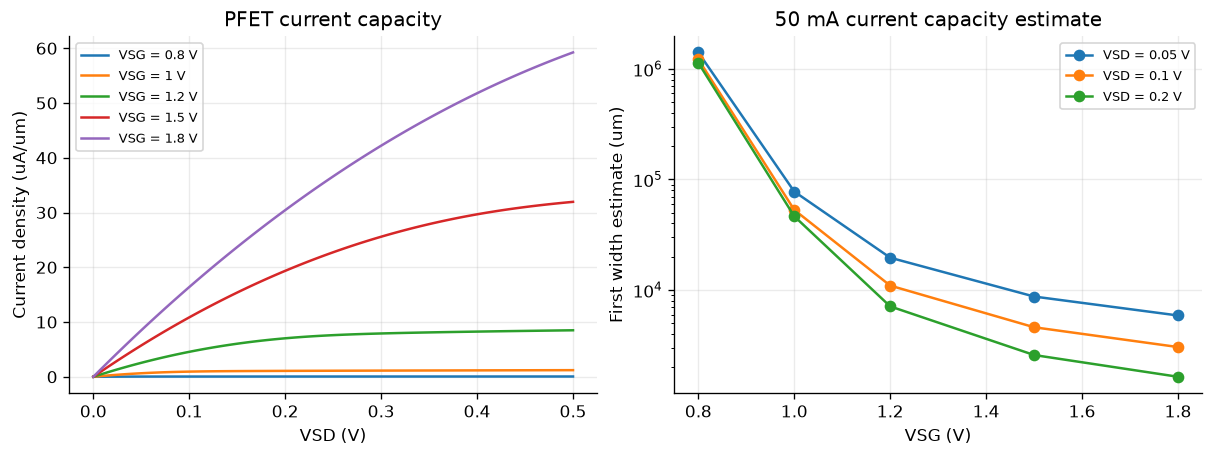

In [4]:
all_figures = lab.figures(load_current_a=TARGET_LOAD_MA / 1000)
display(all_figures['dropout'])
for figure in all_figures.values():
    plt.close(figure)


The horizontal axis on the left is the voltage across the pass device. The colored
curves correspond to different available gate swings. At a fixed dropout voltage,
the driver can therefore change the required pass width substantially.

This explains why choosing the pass width before checking the driver swing can
produce an impractical design. The estimated width must be interpreted together
with the current and voltage that the driver can deliver.


## 3. Static voltage loss and incremental output resistance differ

The static ratio $V_{SD}/I_D$ describes a particular voltage loss and current.
The transistor output resistance describes the local response to a drain voltage
change at fixed gate and source voltages:

$$
r_o=\left(\frac{\partial I_D}{\partial V_{SD}}\right)^{-1}.
$$

For design intuition, the simple long channel triode expression is

$$
I_D\simeq\mu_p C_{ox}\frac WL
\left[(V_{SG}-|V_T|)V_{SD}-\frac{V_{SD}^2}{2}\right].
$$

It gives

$$
\frac{V_{SD}}{I_D}\simeq
\frac{1}{\mu_p C_{ox}(W/L)(V_{SG}-|V_T|-V_{SD}/2)},
\qquad
r_o\simeq
\frac{1}{\mu_p C_{ox}(W/L)(V_{SG}-|V_T|-V_{SD})}.
$$

These expressions apply within the triode approximation. The plotted values below
come from the native compact model, which includes additional effects.
The two resistances are not interchangeable in a supply disturbance derivation.


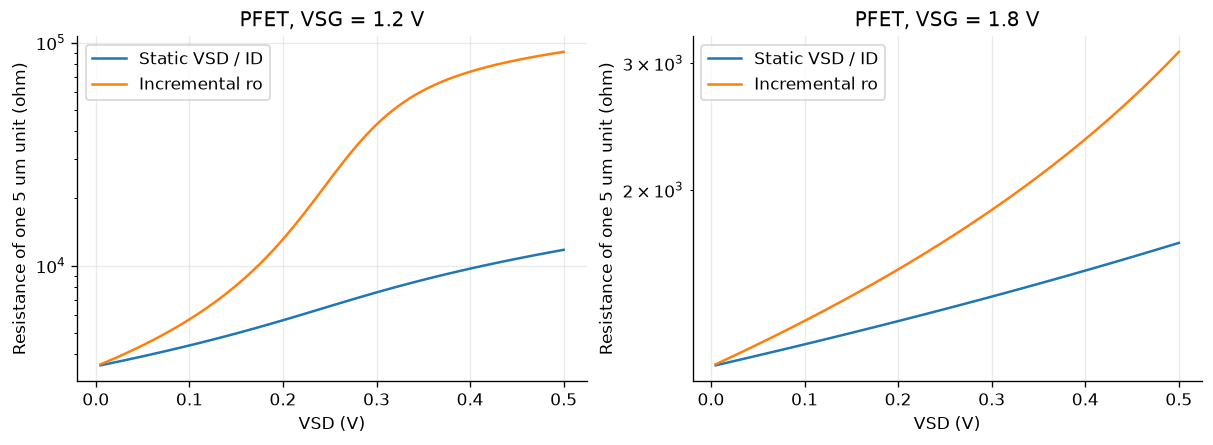

In [5]:
drop = lab.load_dropout()
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), constrained_layout=True)
for axis, gate in zip(axes, [1.2, 1.8]):
    rows = drop[np.isclose(drop.vgs, gate) & (drop.vds > 0) & (drop.id > 1e-9)]
    axis.semilogy(rows.vds, rows.vds / rows.id, label='Static VSD / ID')
    axis.semilogy(rows.vds, rows.ro_ohm, label='Incremental ro')
    axis.set(xlabel='VSD (V)', ylabel='Resistance of one 5 um unit (ohm)',
             title=f'PFET, VSG = {gate:g} V')
    axis.grid(alpha=.25)
    axis.legend()
display(fig)
plt.close(fig)


## 4. Close a transconductance sizing calculation

<img src="figures/fixture_nfet_gmid.png" alt="NFET sizing fixture" width="720">

The NFET source and body are grounded and the drain is held at 0.9 V.
The gate sweep establishes the current, transconductance, output resistance,
and intrinsic gate charge derivative at each bias point.

A target $g_m$ and a selected $g_m/I_D$ first determine the current:

$$
I_D=\frac{g_m}{g_m/I_D}.
$$

For $g_m=100\,\mu\mathrm S$ and $g_m/I_D=15\,\mathrm V^{-1}$,
the target current is $6.667\,\mu\mathrm A$. We obtain an initial width from
the current density at the selected inversion level and drain voltage.


In [6]:
GM_TARGET = 100e-6
GM_ID_TARGET = 15.0
point = lab.lookup_at_gm_id('nmos', length_um=.3, drain_v=.9, gm_id=GM_ID_TARGET)
target_current = GM_TARGET / GM_ID_TARGET
initial_width = target_current / point['id_w']
display(pd.Series({'target_gm_uS': GM_TARGET * 1e6,
                   'target_gm_over_Id_per_V': GM_ID_TARGET,
                   'target_current_uA': target_current * 1e6,
                   'initial_width_um': initial_width,
                   'lookup_VGS_V': point['vgs']}, name='First sizing calculation').to_frame())


,First sizing calculation
target_gm_uS,100.000000
target_gm_over_Id_per_V,15.000000
target_current_uA,6.666667
initial_width_um,1.267665
lookup_VGS_V,0.736507


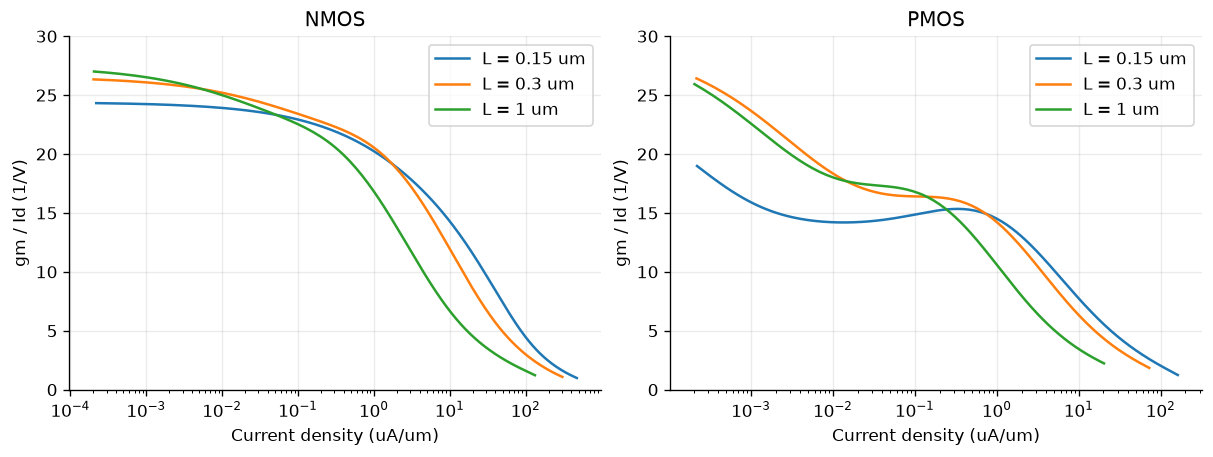

In [7]:
figs = lab.figures()
display(figs['gm_id'])
for figure in figs.values():
    plt.close(figure)


The current density table was measured at a width of 5 micrometers. A smaller
single device is not guaranteed to preserve that density. Width dependent compact
model effects and geometry selection can change the result. This experiment does
not attribute the observed change to a particular internal model parameter.

During the original experiment, each candidate width received a new native gate
sweep. The saved replay interpolates between adjacent samples in each native sweep
to recover the chosen bias. The repeated endpoints are preserved because they are
part of the actual numerical search history.


In [8]:
history = lab.load_sizing_history()
display(history.round(6))
display(lab.sizing_comparison().round(6))
final = lab.sizing_final()
assert abs(final['gm'] / GM_TARGET - 1) < 1e-4
assert abs(final['gm'] / final['id'] - GM_ID_TARGET) < 0.001
print(f"Final native geometry: W = {final['w']:.6f} um, L = {final['l']:.2f} um")
print(f"Recovered gm = {final['gm'] * 1e6:.6f} uS")
print(f"Recovered current = {final['id'] * 1e6:.6f} uA")
print(f"Width change from the density estimate = {(final['w'] / initial_width - 1) * 100:.2f}%")


,iteration,width_um,vgs_v,id_uA,gm_uS,gm_id,error_percent
0,0,0.887365,0.733263,3.349087,50.235750,14.999833,-49.764250
1,1,2.535330,0.744177,12.602251,189.031921,14.999853,89.031921
2,2,0.887365,0.733263,3.349087,50.235750,14.999833,-49.764250
3,3,2.535330,0.744177,12.602251,189.031921,14.999853,89.031921
4,4,1.478230,0.738534,6.595881,98.936656,14.999763,-1.063344
5,5,1.490978,0.738993,6.700891,100.513326,14.999994,0.513326
6,6,1.486828,0.738844,6.666708,99.999793,14.999875,-0.000207
7,7,1.486878,0.738846,6.667120,100.005978,14.999876,0.005978
8,8,1.486828,0.738844,6.666708,99.999793,14.999875,-0.000207


,case,width_um,gate_V,current_uA,gm_uS,gm_id_per_V,evidence
0,Width scaling prediction,1.267665,0.736507,6.666667,100.000000,15.000000,Initial calculation from native lookup current...
1,Actual first geometry,1.267665,0.736507,5.299537,77.831593,14.686490,Interpolation of native sweep at predicted gat...
2,Sizing closure,1.486828,0.738844,6.666708,99.999793,14.999875,Native final geometry sweep with gm/Id restored


Final native geometry: W = 1.486828 um, L = 0.30 um
Recovered gm = 99.999793 uS
Recovered current = 6.666708 uA
Width change from the density estimate = 17.29%


The recovered width is approximately 1.48683 micrometers. This is a continuous
numerical sizing point. A physical design must choose a legal geometry and repeat
the same check after quantization and connection to the intended bias circuit.
The saved final sweep validates this isolated device target at the declared bias.


## 5. Measure the gate loading seen by the driver

<img src="figures/fixture_nfet_loading.png" alt="NFET terminal loading fixture" width="720">

A unit AC voltage is applied to the gate while the drain and source are held at
their declared DC bias and at AC ground. The negative current through the gate
bias source is the current entering the transistor gate.
The measured gate capacitance is

$$
C_{\mathrm{gate,terminal}}(\omega)
=\frac{\operatorname{Im}(i_g/v_g)}{\omega}.
$$

The small capacitance model gives

$$
i_g=sC_{gs}(v_g-v_s)+sC_{gd}(v_g-v_d).
$$

With drain and source fixed, the driver sees approximately $C_{gs}+C_{gd}$.
When those terminals move in a connected circuit, the actual loading changes.
An intrinsic operating point capacitance is therefore not automatically the full
gate load. The native terminal experiment includes the wrapper and its specified
geometry. It does not include layout routing.


,device,frequency_Hz,intrinsic_Cgg_fF,terminal_Cgate_fF,terminal_to_intrinsic_ratio
0,nmos,10000.0,7.70626,10.16928,1.31961
1,pmos,10000.0,7.18910,7.92516,1.10238


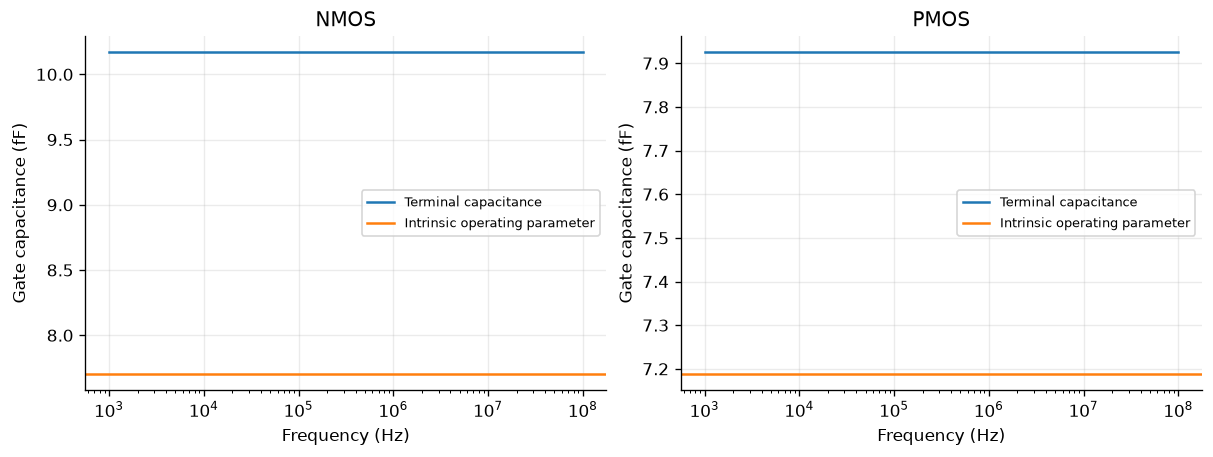

In [9]:
terminal = lab.terminal_summary()
display(pd.DataFrame({'device': terminal.kind,
                      'frequency_Hz': terminal.frequency_hz,
                      'intrinsic_Cgg_fF': terminal.cgg_intrinsic_op_f * 1e15,
                      'terminal_Cgate_fF': terminal.cgg_terminal_f * 1e15,
                      'terminal_to_intrinsic_ratio': terminal.terminal_to_intrinsic_ratio}).round(5))
figs = lab.figures()
display(figs['terminal_loading'])
for figure in figs.values():
    plt.close(figure)


The native NFET terminal capacitance is about 32% larger than the reported intrinsic
quantity at this bias. The PFET difference is about 10%.
These are local fixture results. The terminal capacitance data here use a drain
voltage magnitude of 0.9 V, so they must not be substituted directly into the
100 mV dropout fixture without recharacterizing that bias.

For a resistive driver and terminals that remain fixed, a first gate pole estimate is

$$
f_g\simeq\frac{1}{2\pi R_{\mathrm{driver}}(C_{gs}+C_{gd})}.
$$

For a finite gate transition, the driver must also deliver charge. If a constant
capacitance approximation is justified, $\Delta Q\simeq C\Delta V$ and
$\Delta t\simeq\Delta Q/I_{\mathrm{driver}}$. A real large transition requires
the voltage dependent charge and actual source and sink current.
The current capacity calculation and the gate driving calculation therefore belong
in the same sizing loop.


## 6. What this changes in an LDO design decision

1. Choose the intended load current and pass source to drain voltage.
2. Establish the gate voltage range that a physical driver can provide.
3. Characterize the pass unit at those terminal voltages and choose a unit count.
4. Measure gate loading at the relevant operating points.
5. Size the amplifier and driver, then close the bias and transconductance checks.
6. Connect the complete regulator and verify regulation, supply response, stability,
   startup, and both directions of load change over the intended conditions.

This notebook completes the native device evidence for the first sizing decisions.
It does not replace step 6. In particular, a pass transistor current capacity result
alone cannot determine closed loop PSR or output impedance.

The examples reveal two distinct mistakes: treating a selected gate voltage as
available without checking its driver, and treating a width estimate as a validated
device after changing its geometry. Both can be detected before a full regulator is assembled.


## 7. Reproduce or regenerate

**Saved evidence mode, used by Run All:** the notebook reads the included native
tables, verifies hashes, and repeats the calculations and plots. It does not silently
invoke a circuit simulator. This mode was used for the submitted executed notebook.

**Fresh native mode:** install ngspice and the public SKY130 PDK, then set
`SKY130_MODEL` to `sky130.lib.spice`, or set `PDK_ROOT` to the directory containing
`sky130A`. Set `NGSPICE` if the executable is not on PATH. The documented historical
model package and hash are in `FOUNDATIONAL_EVIDENCE.json`.

The command below creates a new output directory and runs the actual transistor
decks. It does not overwrite the frozen tables. Existing nonempty output directories
are rejected to prevent accidental reuse of stale results.

```text
python scripts/device_lab.py regenerate --output work/device_run
```

The next cell is deliberately disabled by default. Enable it only after configuring
the native tools. A fresh run is evidence of that installed model and simulator version.
The notebook does not present fresh runs as completed when only saved data were read.


In [10]:
RUN_NATIVE = False
if RUN_NATIVE:
    fresh = lab.regenerate(PROJECT / 'work' / 'device_run')
    display(fresh)
else:
    print('Saved evidence mode. No new native circuit simulation was launched.')


Saved evidence mode. No new native circuit simulation was launched.


In [11]:
# Record the environment used to analyze the saved data, separately from the original simulator.
from importlib.metadata import version
display(pd.Series({'Python': sys.version.split()[0],
                   'NumPy': version('numpy'), 'pandas': version('pandas'),
                   'Matplotlib': version('matplotlib'),
                   'analysis_mode': 'Saved native evidence'}, name='Notebook execution environment').to_frame())


,Notebook execution environment
Python,3.12.14
NumPy,2.5.4
pandas,3.0.1
Matplotlib,3.11.2
analysis_mode,Saved native evidence


## References, attribution, and scope

1. [SkyWater SKY130 device documentation](https://skywater-pdk.readthedocs.io/en/main/rules/device-details.html).
2. [ngspice documentation](https://ngspice.sourceforge.io/docs.html).
3. [Boris Murmann, Chipathon 2024 sizing examples](https://github.com/bmurmann/Chipathon2024).
   These examples informed the educational use of device lookup data and transconductance efficiency.
   This submission uses its own characterization fixtures, saved data, and portable analysis module.
4. [SSCS Code a Chip program](https://github.com/sscs-ose/sscs-ose-code-a-chip.github.io).
5. [Kwantae Kim, cirfig_gen](https://github.com/KwantaeKim/cirfig_gen), MIT licensed circuit symbols.
   The symbol notice is included with the figures.

The native simulations were created for the author's SKY130 learning project and
are curated here with their source hashes. No private foundry model is included.
The notebook and original code are distributed under Apache License 2.0.
Third party symbols retain their stated license.

AI assistance was used for notebook preparation, code adaptation, and checking.
Every device curve presented as a circuit result comes from the identified native
ngspice data. Analytical expressions are explanatory approximations, and no silicon
measurement or complete LDO qualification is claimed.
